### Inference (1D)

Loads a trained 1D run from `out/<run_name>/`, restores checkpoint weights, and runs sampling.

Supports `flow_matching` and `flow_map` checkpoints through the shared family sampling API. Start the kernel from the repository root or `scripts/`.


In [ ]:
from pathlib import Path
import sys

# Support kernels started from either the repository root or scripts/.
repo_root = next(
    (path for path in (Path.cwd(), Path.cwd().parent) if (path / "src" / "joint").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start this notebook from the repository root or scripts/.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from einops import rearrange

from joint.config import get_config
from joint.generative import build_model_family
from joint.train import get_optimiser, load_training_state
from joint.utils import ModalitySpec, ModalityInfos, count_parameters


In [39]:
run_name = "0_1d"
out_dir = repo_root / "out" / run_name
config_path = out_dir / "config.json"
train_state_path = out_dir / "train_state.eqx"

if not config_path.exists():
    raise FileNotFoundError(f"Missing config file: {config_path}")
if not train_state_path.exists():
    raise FileNotFoundError(f"Missing checkpoint file: {train_state_path}")

config = get_config(config_path, reload=True)
key = jr.key(config.seed)

print(f"Loading run '{run_name}' from {out_dir}")


Loading run '0_1d' from ../out/0_1d


In [ ]:
# Recreate synthetic 1D dataset exactly as in main_1d.py for comparison plots.
image_shape = (config.data_config.n_channels, config.data_config.n_pix)
backbone_config = config.model_config.backbone
num_patches = config.data_config.n_pix // backbone_config.patch_size
val_fraction = float(getattr(config.data_config, "val_fraction", 0.1))

key_A, key_B = jr.split(key)
A = jr.uniform(key_A, (config.data_config.n_samples,), minval=1.0, maxval=4.0)
B = jr.uniform(key_B, (config.data_config.n_samples,), minval=1.0, maxval=4.0) * -1.0


def grf1d_powerlaw(
    key,
    A: float,
    B: float,
    n: int,
    L: float,
    k0: float = 1.0,
    mean: float = 0.0,
    zero_mode: float = 0.0,
    eps: float = 1e-12,
):
    k = 2.0 * jnp.pi * jnp.fft.rfftfreq(n, d=L / n)
    Pk = A * jnp.power((jnp.maximum(k, eps) / k0), B)

    key_re, key_im = jr.split(key, 2)
    re = jr.normal(key_re, shape=Pk.shape)
    im = jr.normal(key_im, shape=Pk.shape)
    F = (re + 1j * im) * jnp.sqrt(Pk / 2.0)
    F = F.at[0].set(zero_mode + 0.0j)
    if n % 2 == 0:
        F = F.at[-1].set(jnp.real(F[-1]) + 0.0j)

    field = jnp.fft.irfft(F, n=n)
    field = field * jnp.sqrt(n)
    return field + mean


def generator(_key, a, b):
    return grf1d_powerlaw(
        _key,
        n=config.data_config.n_pix,
        L=1.0,
        A=a,
        B=b,
        k0=2.0 * jnp.pi,
    )


keys = jr.split(key, len(A))
X = jax.vmap(generator)(keys, A, B)
X = X[:, jnp.newaxis, :]
X_mean = jnp.mean(X, axis=0)
X_std = jnp.std(X, axis=0)
X = (X - X_mean) / X_std
Y_raw = jnp.stack([A, B], axis=1)
Y_mean = jnp.mean(Y_raw, axis=0, keepdims=True)
Y_std = jnp.std(Y_raw, axis=0, keepdims=True)
Y_std = jnp.where(Y_std > 0.0, Y_std, 1.0)
Y = (Y_raw - Y_mean) / Y_std

n_samples = len(X)
n_valid = max(1, int(n_samples * val_fraction))
n_valid = min(n_valid, n_samples - 1)
n_train = n_samples - n_valid

key, key_split = jr.split(key)
idx = jr.permutation(key_split, n_samples)
train_idx = idx[:n_train]
valid_idx = idx[n_train:]
X_train, Y_train = X[train_idx], Y[train_idx]
X_valid, Y_valid = X[valid_idx], Y[valid_idx]
Y_train_raw, Y_valid_raw = Y_raw[train_idx], Y_raw[valid_idx]
x_plot_vmin, x_plot_vmax = [
    float(v) for v in jnp.percentile(X_train, jnp.array([1.0, 99.0]))
]

key, key_ref_idx = jr.split(key)
ref_idx = int(jr.randint(key_ref_idx, shape=(), minval=0, maxval=len(X_train)))
x_ref_train = X_train[ref_idx]
a_ref = Y_train[ref_idx, 0]
b_ref = Y_train[ref_idx, 1]
a_ref_raw = a_ref * Y_std[0, 0] + Y_mean[0, 0]
b_ref_raw = b_ref * Y_std[0, 1] + Y_mean[0, 1]


In [ ]:
# Rebuild model skeleton and load checkpoint.
modality_infos = ModalityInfos(
    {
        "x": ModalitySpec(
            name="x",
            modality_type="image",
            input_shape=image_shape,
            patch_size=backbone_config.patch_size,
            sequence_length=num_patches,
            embedding_dim=backbone_config.embedding_dim,
        ),
        "a": ModalitySpec(
            name="a",
            modality_type="vector",
            input_shape=(1,),
            sequence_length=1,
            embedding_dim=backbone_config.embedding_dim,
        ),
        "b": ModalitySpec(
            name="b",
            modality_type="vector",
            input_shape=(1,),
            sequence_length=1,
            embedding_dim=backbone_config.embedding_dim,
        ),
    }
)

if str(config.model_config.model_family) not in {"flow_matching", "flow_map"}:
    raise ValueError("These notebooks expect a flow_matching or flow_map run.")

key, key_model = jr.split(key)
family = build_model_family(config, modality_infos, key_model)
v = family.model

opt = get_optimiser(v, config.train_config)
opt_state = opt.init(eqx.filter(v, eqx.is_inexact_array))
v, v_ema, _, _, step = load_training_state(
    train_state_path,
    use_ema=bool(config.train_config.use_ema),
    model=v,
    optimiser=opt,
    optimiser_state=opt_state,
)
v_infer = eqx.nn.inference_mode(v_ema if v_ema is not None else v)

print(f"Model parameters: {count_parameters(v_infer):.3E}")
print(f"Loaded train step: {step}")


#### Compare generated to simulated data

In [ ]:
# 1) Unconditional multimodal sampling: generated x vs real train x.
sample_n_samples = config.sampling_config.n_samples

Z = {
    name: jr.normal(jr.fold_in(key, i), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}

key, key_sample = jr.split(key)
sample_keys = jr.split(key_sample, sample_n_samples ** 2)
sample_fn = lambda z, sample_key: family.sample_fn(v_infer, z, sample_key)
samples_dict = jax.vmap(sample_fn)(Z, sample_keys)
generated_samples = samples_dict["x"][:, 0, :]

key, key_train_pick = jr.split(key)
train_pick = jr.choice(key_train_pick, len(X_train), shape=(sample_n_samples ** 2,))
train_samples = X_train[train_pick, 0, :]

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].imshow(
    generated_samples,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0].set_title("Generated x")
axs[1].imshow(
    train_samples,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[1].set_title("Real train x")
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()


#### Generated to simulated (fixed physics parameters)

In [ ]:
# 2) Conditional tests (same as main_1d.py):
#    - sample x with fixed a,b
#    - sample a,b with fixed x

Z_fixed_ab = {
    name: jr.normal(jr.fold_in(key, i), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_fixed_ab["a"] = jnp.full((sample_n_samples ** 2, 1), a_ref)
Z_fixed_ab["b"] = jnp.full((sample_n_samples ** 2, 1), b_ref)

key, key_cond_ab = jr.split(key)
cond_keys_ab = jr.split(key_cond_ab, sample_n_samples ** 2)
sample_fn_fixed_ab = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["x"], sample_key)
samples_fixed_ab = jax.vmap(sample_fn_fixed_ab)(Z_fixed_ab, cond_keys_ab)
generated_x_fixed_ab = samples_fixed_ab["x"][:, 0, :]

x_fixed = X_valid[:1]
Z_fixed_x = {
    name: jr.normal(jr.fold_in(key, i + 100), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_fixed_x["x"] = jnp.repeat(x_fixed, sample_n_samples ** 2, axis=0)

key, key_cond_x = jr.split(key)
cond_keys_x = jr.split(key_cond_x, sample_n_samples ** 2)
sample_fn_fixed_x = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["a", "b"], sample_key)
samples_fixed_x = jax.vmap(sample_fn_fixed_x)(Z_fixed_x, cond_keys_x)
generated_a_grid = rearrange(samples_fixed_x["a"], "(p q) 1 -> p q", p=sample_n_samples)
generated_b_grid = rearrange(samples_fixed_x["b"], "(p q) 1 -> p q", p=sample_n_samples)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs[0, 0].imshow(
    generated_x_fixed_ab,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0, 0].set_title(f"Generated x | fixed a,b=({float(a_ref_raw):.2f}, {float(b_ref_raw):.2f})")
axs[0, 1].plot(x_ref_train[0], color="black", linewidth=1.5)
# axs[0, 1].plot(generated_x_fixed_ab, linewidth=1.5, color="royalblue")
axs[0, 1].set_ylim(float(X_train.min()), float(X_train.max()))
axs[0, 1].set_title("Real train x (same a,b)")

generated_a_grid_raw = generated_a_grid * Y_std[0, 0] + Y_mean[0, 0]
generated_b_grid_raw = generated_b_grid * Y_std[0, 1] + Y_mean[0, 1]
axs[1, 0].imshow(generated_a_grid_raw, cmap="viridis", vmin=Y_train_raw[:, 0].min(), vmax=Y_train_raw[:, 0].max())
axs[1, 0].set_title("Generated a (raw) | fixed x")
axs[1, 1].imshow(generated_b_grid_raw, cmap="viridis", vmin=Y_train_raw[:, 1].min(), vmax=Y_train_raw[:, 1].max())
axs[1, 1].set_title("Generated b (raw) | fixed x")

for row in axs:
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
fig.tight_layout()
plt.show()


#### Posterior sampling for posterior predictive

Given observed conditioning data $x_{\mathrm{obs}}$, the posterior predictive for a new realization $x_{\mathrm{new}}$ is
$$
p(x_{\mathrm{new}} \mid x_{\mathrm{obs}})
= \int p(x_{\mathrm{new}} \mid a,b)\, p(a,b \mid x_{\mathrm{obs}})\, \text{d}a\, \text{d}b.
$$

A Monte Carlo estimator with $S$ samples is:

1. Draw $\theta^{(s)}=(a^{(s)}, b^{(s)}) \sim p(a,b \mid x_{\mathrm{obs}})$ for $s=1,\dots,S$.
2. Draw $x_{\mathrm{new}}^{(s)} \sim p(x \mid \theta^{(s)})$.

Then
$$
p(x_{\mathrm{new}} \mid x_{\mathrm{obs}})
\approx \frac{1}{S} \sum_{s=1}^S \delta\!\left(x_{\mathrm{new}} - x_{\mathrm{new}}^{(s)}\right),
$$
and for any summary/statistic $f$,
$$
\mathbb{E}[f(x_{\mathrm{new}}) \mid x_{\mathrm{obs}}]
\approx \frac{1}{S} \sum_{s=1}^S f\!\left(x_{\mathrm{new}}^{(s)}\right).
$$


In [ ]:
# 3) Sample many (a, b) given a randomly selected training x.
n_ab_samples = 10_000

key, key_rand_x, key_noise = jr.split(key, 3)
rand_x_idx = int(jr.randint(key_rand_x, shape=(), minval=0, maxval=len(X_train)))
x_anchor = X_train[rand_x_idx : rand_x_idx + 1]
a_true_norm = float(Y_train[rand_x_idx, 0])
b_true_norm = float(Y_train[rand_x_idx, 1])
a_true = float(Y_train_raw[rand_x_idx, 0])
b_true = float(Y_train_raw[rand_x_idx, 1])

Z_many_ab = {
    name: jr.normal(jr.fold_in(key_noise, i + 200), (n_ab_samples, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_many_ab["x"] = jnp.repeat(x_anchor, n_ab_samples, axis=0)

key, key_cond_many = jr.split(key)
cond_keys_many = jr.split(key_cond_many, n_ab_samples)
sample_fn_many_ab = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["a", "b"], sample_key)

samples_many_ab = jax.vmap(sample_fn_many_ab)(Z_many_ab, cond_keys_many)
a_samples_norm = samples_many_ab["a"][:, 0]
b_samples_norm = samples_many_ab["b"][:, 0]
a_samples = a_samples_norm * Y_std[0, 0] + Y_mean[0, 0]
b_samples = b_samples_norm * Y_std[0, 1] + Y_mean[0, 1]


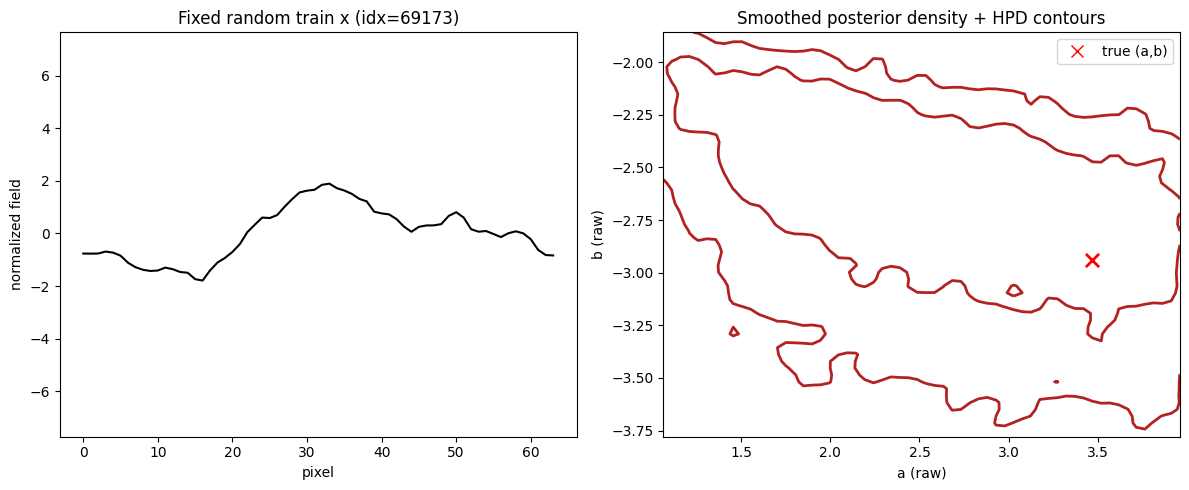

In [45]:
# 3b) Smoothed HPD contours on the same posterior samples (separate test cell).
# Reuses: x_anchor, rand_x_idx, a_true, b_true, a_samples, b_samples from cell 3.

if "a_samples" not in globals() or "b_samples" not in globals():
    raise RuntimeError("Run cell 3 first to generate posterior samples.")

# Build a histogram in a robust plotting range, then smooth it in bin-space.
a_np = np.asarray(a_samples)
b_np = np.asarray(b_samples)
a_lo, a_hi = np.percentile(a_np, [0.5, 99.5])
b_lo, b_hi = np.percentile(b_np, [0.5, 99.5])

bins = 60
hist, x_edges, y_edges = np.histogram2d(
    a_np,
    b_np,
    bins=bins,
    range=[[a_lo, a_hi], [b_lo, b_hi]],
)
prob_raw = hist / np.sum(hist)


def gaussian_kernel1d(sigma: float, radius: int) -> np.ndarray:
    x = np.arange(-radius, radius + 1)
    k = np.exp(-0.5 * (x / sigma) ** 2)
    return k / np.sum(k)


def smooth_hist2d(arr: np.ndarray, sigma: float = 1.2) -> np.ndarray:
    radius = max(1, int(round(3.0 * sigma)))
    k = gaussian_kernel1d(sigma, radius)
    sm = np.apply_along_axis(lambda m: np.convolve(m, k, mode="same"), axis=0, arr=arr)
    sm = np.apply_along_axis(lambda m: np.convolve(m, k, mode="same"), axis=1, arr=sm)
    return sm


prob = smooth_hist2d(prob_raw, sigma=1.2)
prob = prob / np.sum(prob)

# HPD levels from smoothed density.
flat = prob.ravel()
order = np.argsort(flat)[::-1]
cdf = np.cumsum(flat[order])
idx68 = min(np.searchsorted(cdf, 0.68), len(flat) - 1)
idx95 = min(np.searchsorted(cdf, 0.95), len(flat) - 1)
h68 = flat[order][idx68]
h95 = flat[order][idx95]

x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
Xc, Yc = np.meshgrid(x_centers, y_centers, indexing="xy")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(np.asarray(x_anchor[0, 0]), color="black", linewidth=1.5)
axs[0].set_title(f"Fixed random train x (idx={rand_x_idx})")
axs[0].set_xlabel("pixel")
axs[0].set_ylabel("normalized field")
axs[0].set_ylim(float(X_train.min()), float(X_train.max()))

# mesh = axs[1].pcolormesh(x_edges, y_edges, prob.T, shading="auto", cmap="gray_r")
# cbar = fig.colorbar(mesh, ax=axs[1], pad=0.02)
# cbar.set_label("smoothed density")

axs[1].contour(
    Xc,
    Yc,
    prob.T,
    levels=[h95, h68],
    colors=["firebrick", "firebrick"],
    linestyles=["-", "-"],
    linewidths=2,
)
axs[1].scatter([a_true], [b_true], c="red", marker="x", s=90, linewidths=2)
axs[1].set_xlabel("a (raw)")
axs[1].set_ylabel("b (raw)")
axs[1].set_title("Smoothed posterior density + HPD contours")
legend_handles = [
    # Line2D([0], [0], color="firebrick", lw=2, label="68% HPD contour"),
    # Line2D([0], [0], color="firebrick", lw=2, linestyle="--", label="95% HPD contour"),
    Line2D([0], [0], marker="x", linestyle="None", color="red", markersize=8, label="true (a,b)"),
]
axs[1].legend(handles=legend_handles, loc="best")

fig.tight_layout()
plt.show()


In [46]:
a_samples.shape

(10000,)

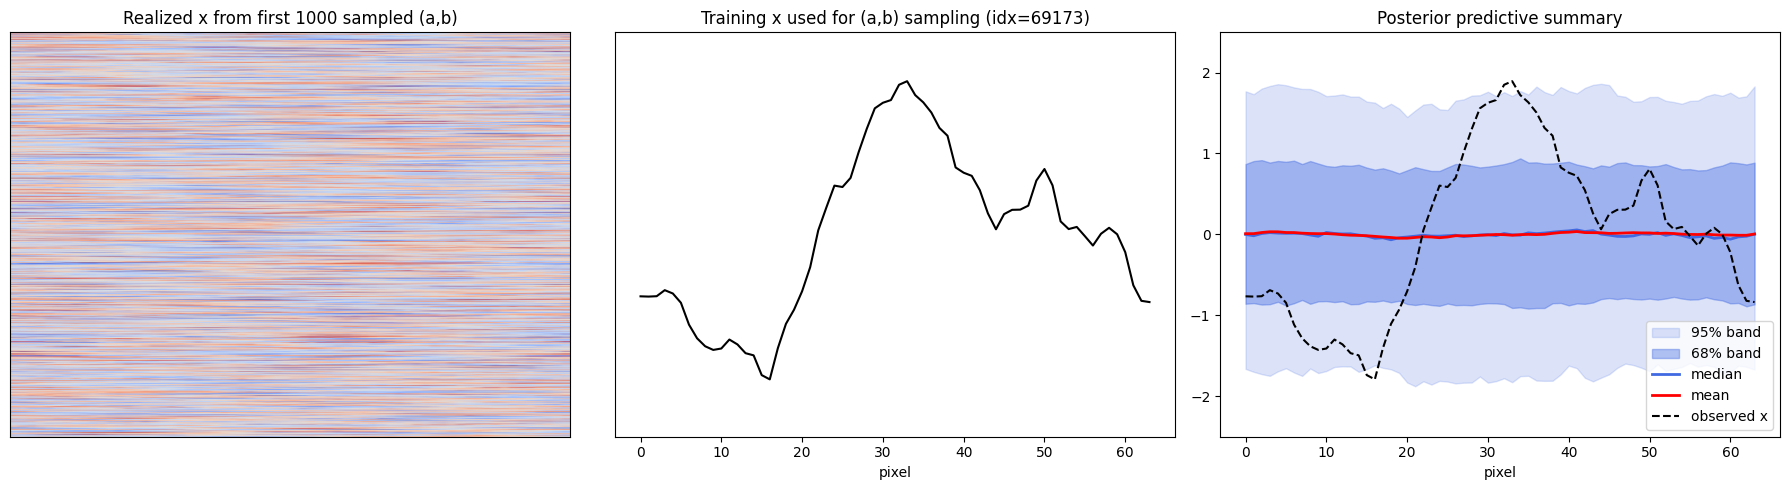

In [47]:
# 4) From sampled (a,b), generate real x realizations for first N**2 and summarize posterior predictive uncertainty.
N = sample_n_samples
n_panel = 1_000 # N ** 2
if len(a_samples) < n_panel:
    raise ValueError(f"Need at least {n_panel} sampled pairs, got {len(a_samples)}")

a_panel = a_samples[:n_panel]
b_panel = b_samples[:n_panel]

key, key_real_panel = jr.split(key)
real_keys = jr.split(key_real_panel, n_panel)

# Sample real fields from the simulator using sampled parameter pairs.
x_real_panel = jax.vmap(generator)(real_keys, a_panel, b_panel)
x_real_panel = x_real_panel[:, jnp.newaxis, :]
x_real_panel = (x_real_panel - X_mean) / X_std

x_real_grid = np.asarray(x_real_panel[:, 0, :])
x_anchor_1d = np.asarray(x_anchor[0, 0])

# Posterior predictive summary bands at each pixel.
x_med = np.percentile(x_real_grid, 50.0, axis=0)
x_mean = np.mean(x_real_grid, axis=0)
x_lo68 = np.percentile(x_real_grid, 16.0, axis=0)
x_hi68 = np.percentile(x_real_grid, 84.0, axis=0)
x_lo95 = np.percentile(x_real_grid, 2.5, axis=0)
x_hi95 = np.percentile(x_real_grid, 97.5, axis=0)
pixels = np.arange(x_real_grid.shape[1])

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(
    x_real_grid,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0].set_title(f"Realized x from first {n_panel} sampled (a,b)")
axs[0].set_xticks([])
axs[0].set_yticks([])

axs[1].plot(x_anchor_1d, color="black", linewidth=1.5)
axs[1].set_title(f"Training x used for (a,b) sampling (idx={rand_x_idx})")
axs[1].set_xlabel("pixel")
axs[1].set_ylim(x_plot_vmin, x_plot_vmax)
axs[1].set_yticks([])

axs[2].fill_between(pixels, x_lo95, x_hi95, color="royalblue", alpha=0.18, label="95% band")
axs[2].fill_between(pixels, x_lo68, x_hi68, color="royalblue", alpha=0.4, label="68% band")
axs[2].plot(pixels, x_med, color="royalblue", linewidth=2.0, label="median")
axs[2].plot(pixels, x_mean, color="red", linewidth=2.0, label="mean")
axs[2].plot(pixels, x_anchor_1d, color="black", linestyle="--", linewidth=1.5, label="observed x")
axs[2].set_title("Posterior predictive summary")
axs[2].set_xlabel("pixel")
axs[2].set_ylim(x_plot_vmin, x_plot_vmax)
axs[2].legend(loc="best")

fig.tight_layout()
plt.show()
